In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot-only notebook: the numbers are produced by `python postprocess.py` (-> ./data/*.csv)
os.makedirs('../plots', exist_ok=True)

In [2]:
df = pd.read_csv('data/inp_dis_10k_comp.csv')

In [3]:
inpuDist = ['random', 'c6m_low_acc', 'cifar10', 'cifar6m', 'c6m_high_acc']

In [4]:
layers = ['conv1', 'conv2', 'conv3', 'conv4', 'conv5', 'conv6', 'fc1', 'fc2']
err = df.set_index(['leakage', 'input_dist', 'layer'])['error_prob']
layersDict_per_leak_mod = {leak_mod: {layer: [err[leak_mod, inpu, layer] for inpu in inpuDist] for layer in layers}
                           for leak_mod in ['HD', 'HW']}

In [5]:
legend = [
    "Random",
    "CIFAR-5M (low-acc)",
    "CIFAR-10",
    "CIFAR-5M",
    "CIFAR-5M (high-acc)",
]

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def plot_misextraction_simple(
    layers, layersDict, legend,
    figsize=(16, 13),
    font_size=30,
    base_jitter=0.1,
    max_jitter=0.3,
    leak_model='HD',
    markers=None,
    yscale="symlog",          # "linear" or "symlog"
    symlog_linthresh=2e-5,
    symlog_linscale=1.0
):
    """
    Scatter plot with deterministic jitter.
    - Different marker shapes per legend/color index.
    - yscale flag: "linear" or "symlog".
    """

    x_positions = list(range(len(layers)))

    # Colors
    c1 = plt.get_cmap('tab20').colors
    c2 = plt.get_cmap('tab20b').colors
    c3 = plt.get_cmap('tab20c').colors
    colors = (list(c1) + list(c2) + list(c3))[::2]

    # Marker shapes (cycled if needed)
    if markers is None:
        markers = ["o", "s", "^", "D", "v", "P", "X", "*", "<", ">", "h", "H", "p", "8", "+", "x"]
    markers = [markers[i % len(markers)] for i in range(len(legend))]

    fig, ax = plt.subplots(figsize=figsize)

    for j, layer in enumerate(layers):
        y = np.array(layersDict[layer], dtype=float)

        # Count duplicates for deterministic jitter
        unique_vals, counts = np.unique(y, return_counts=True)
        count_map = dict(zip(unique_vals, counts))

        jitter = np.zeros_like(y, dtype=float)
        for yi, cnt in count_map.items():
            if cnt > 1:
                scale = min(base_jitter * (cnt - 1), max_jitter)
                offsets = np.linspace(-scale, scale, cnt)
                idxs = np.where(y == yi)[0]
                for off, idx in zip(offsets, idxs):
                    jitter[idx] = off

        # Plot each point with its (color,marker) index
        for i, yi in enumerate(y):
            ax.scatter(
                j + jitter[i],
                yi,
                s=300,
                marker=markers[i % len(markers)],
                color=colors[i % len(colors)]
            )

    # ---- Y scale flag ----
    if yscale.lower() in ("symlog", "semilog", "semilogy"):
        ax.set_yscale("symlog", linthresh=symlog_linthresh, linscale=symlog_linscale)
    elif yscale.lower() == "linear":
        ax.set_yscale("linear")
        ax.set_ylim(-0.01, min(1.05, np.nanmax([np.nanmax(layersDict[L]) for L in layers]) * 1.1))
    else:
        raise ValueError("yscale must be 'linear' or 'symlog'")

    # X ticks / labels
    ax.set_xticks(x_positions)
    ax.set_xticklabels(layers, rotation=-45, fontsize=font_size)

    ax.set_xlabel("Network Layer", fontsize=font_size)
    ax.set_ylabel("Error Probability", fontsize=font_size)

    # Legend: match both color and shape
    handles = [
        ax.scatter([], [], s=250, c=[colors[i % len(colors)]], marker=markers[i])
        for i in range(len(legend))
    ]
    ax.legend(handles, legend, fontsize=font_size-4, title_fontsize=font_size)

    ax.grid(True, linestyle="--", alpha=0.5)
    ax.tick_params(axis="y", labelsize=font_size)

    plt.tight_layout()
    plt.savefig(
        f"../plots/inp_dist_comp_10k_{leak_model}.pdf",
        format="pdf",
        bbox_inches="tight",
        metadata={"Creator": "Matplotlib"}
    )
    return fig, ax

(<Figure size 1600x1300 with 1 Axes>,
 <Axes: xlabel='Network Layer', ylabel='Error Probability'>)

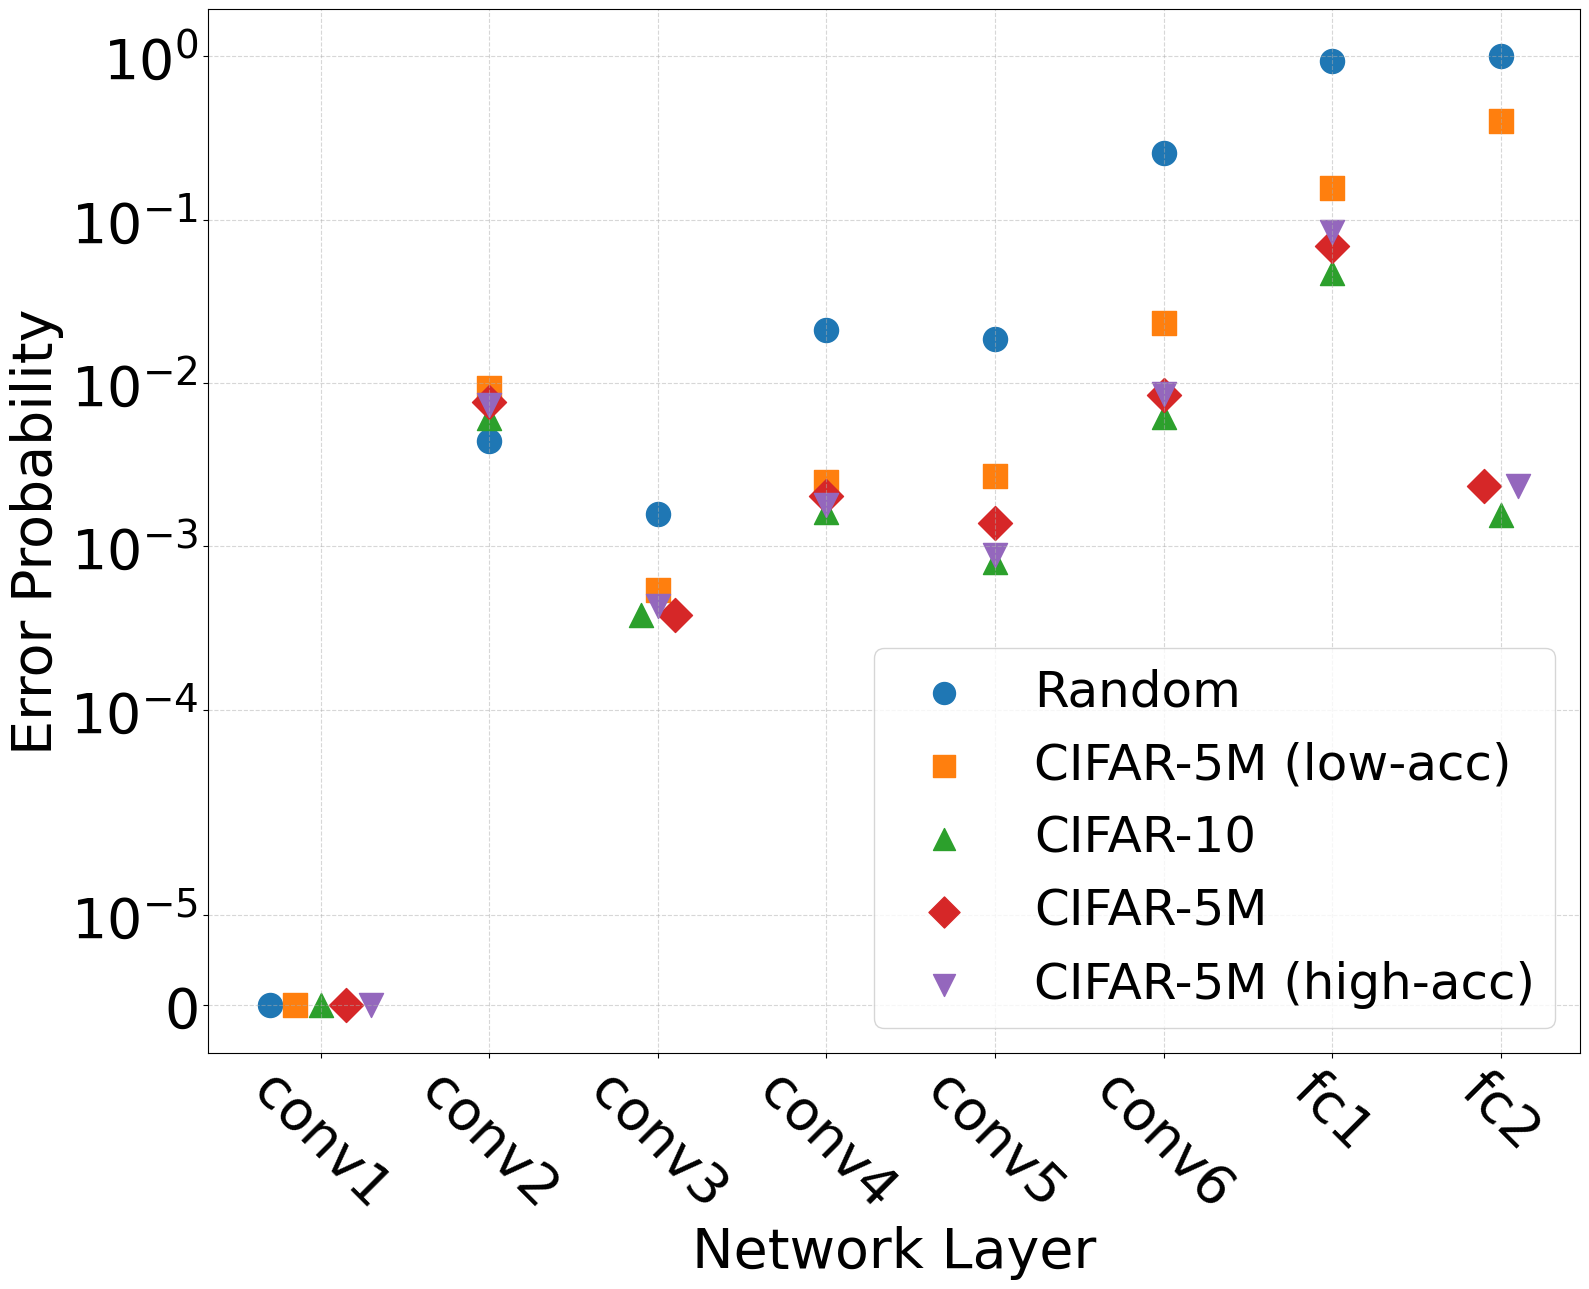

In [7]:
plot_misextraction_simple(layers, layersDict_per_leak_mod['HD'], legend, font_size=40, leak_model = 'HD')

(<Figure size 1600x1300 with 1 Axes>,
 <Axes: xlabel='Network Layer', ylabel='Error Probability'>)

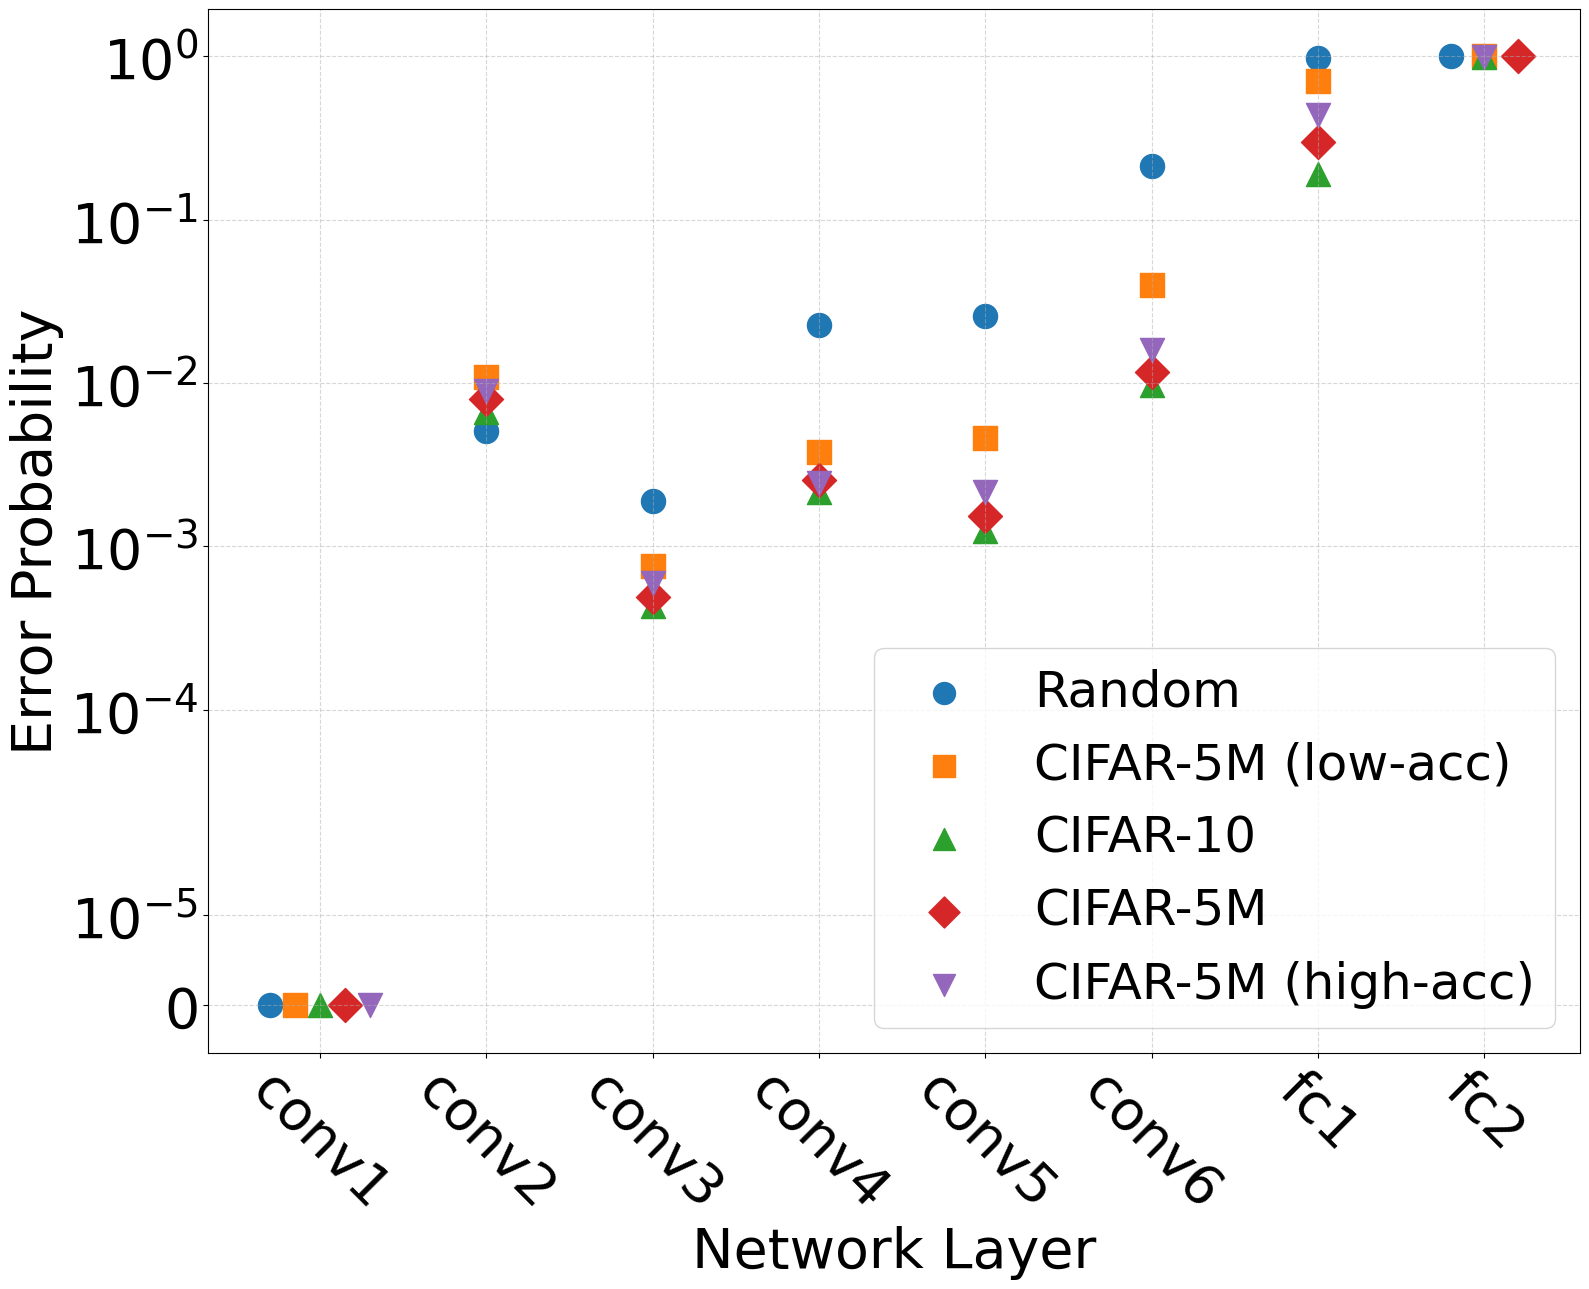

In [8]:
plot_misextraction_simple(layers, layersDict_per_leak_mod['HW'], legend, font_size=40, leak_model = 'HW')